# Experiment design pipeline for two-qubit GST: shots, circuits and depth from the Fisher information

This notebook turns the Fisher-information analysis into a design choice $(N, m, L_{\max})$:
- $N$: number of circuits;
- $m$: shots per circuit;
- $L_{\max}$: maximum sequence length, with `seq_len_list = [1, L_max // 2 + 1, L_max]`.

It is the follow-up of [`ptm_precision_design_2q.ipynb`](ptm_precision_design_2q.ipynb) (left unchanged) and [`depth_check_2q.ipynb`](depth_check_2q.ipynb). Theory: [`PTM_PRECISION.md`](identifiability_and_cramer_rao/PTM_PRECISION.md) and [`VALIDITY.md`](identifiability_and_cramer_rao/VALIDITY.md). Error bars on real data come from the bootstrap and are not the subject here.

**Terms.**
- **PTM:** Pauli transfer matrix. The 1440 non-constant elements, gauge-fixed to the target (PTM_PRECISION 2.2).
- **LAN width:** $\sigma^{\rm LAN}_f=\sqrt{\mathbf d_f^\top F^+\mathbf d_f}$, the width under local asymptotic normality. It is exact for $m\to\infty$, and it was conservative in every test so far.
- **vT width:** the van Trees width with prior width $\tau=2\tau_0$ per tangent direction (PTM_PRECISION 3.7). It is a lower bound on the prior-averaged error of any estimator.
- **Rate resolution:** $\sigma(\mu)/\mu$ for the 18 small Choi eigenvalues $\mu$, the incoherent rates. A rate is resolved if $\le0.5$, i.e. $u=\mu/\sigma(\mu)\ge2$ (VALIDITY 4.4).
- **Bias cap:** $3\max_g(1-\mu_{1,g})$, the first-order bound on how far a PTM element moves if the estimate collapses the incoherent part of a gate (PTM_PRECISION 3.5).
- **T3, T4:** refits of simulated data at the chosen design, and the check that a prior guess gives the same design as the truth (PTM_PRECISION §5).

**Decision rule** (per element, 95%: $z=1.96$; target half-width $\delta$):
- **Regime A** (bias cap $<\delta/2$): the unresolved incoherent part cannot spoil $\delta$, so design to $m_{\rm design}=m_{\rm vT}$, with $m_{\rm LAN}$ as the conservative end.
- **Regime B** (otherwise): the rates must be resolved for LAN to hold, so $m_{\rm design}=\max(m_{\rm LAN},m_{\rm rate})$.
- **Constraints:** $m\le10^4$, and $N$ at least about twice the identifiability threshold $n_{\rm id}/(n_{\rm out}-1)=208$.

**Evaluation points.** Each noise strength is computed at the truth (noise seed 42) and at a prior guess (seed 7); in a real experiment only the prior guess exists. Computed by [`scripts/24_design_scan_points.py`](identifiability_and_cramer_rao/scripts/24_design_scan_points.py), one design seed:

| noise strength | regime | $N$ | $L_{\max}$ |
|---|---|---|---|
| 0.05 (hardware-like) | A | 300, 400, 600 | 14, 18, 23, 28, 32 |
| 0.3 | B | 400, 600, 1000 | 14, 18, 23, 28 |

The depths come from the depth check: at noise 0.3 the gain stops at about $L_{\max}=23$, and at noise 0.05 it continues.

## How to read the results

For a candidate $(N, m, L_{\max})$, check in this order:

1. **Estimability is 100%**, and $N\ge2\times208$. Below that the weakest directions are badly conditioned (README 5.2).
2. **Regime** (table below). It tells you which width sets the design.
3. **$m_{\rm design}\le m$**, and the binding constraint: vT (A), or LAN or rates (B).
4. **The bracket $m_{\rm LAN}/m_{\rm vT}$.**
   - Near 1–2: the prior width $\tau$ does not matter and the prediction is tight.
   - Large: the incoherent part is unresolved, and the truth lies between the two (closer to vT at noise 0.05; PTM_PRECISION 3.6).
5. **vT is a floor.** If vT misses $\delta$, more data of that design will not reach it.
6. **Robustness (T4).** The prior guess and the truth should give $m_{\rm design}$ within about 10–20%. If the cheapest design differs, take the more expensive one.
7. **Marginal returns.** The local exponents in $L_{\max}$ and $N$: $-1$ means doubling halves $m$; $-0.3$ means it saves only about 20%.
8. **Cost, not total shots.** The cost is $N\,(r+m)$, with $r$ the cost of one circuit in shots (compilation, upload, reset overhead). The cheapest design moves to smaller $N$ as $r$ grows.
9. **Not in these numbers:**
   - Drift caps the useful $m$ at about $\bar p\bar q/V$ (last section).
   - Leakage and non-Markovian noise grow with depth.
   - Whether the optimizer finds the right basin. T3 tests this.

In [1]:
import sys
sys.path.append("identifiability_and_cramer_rao/scripts")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ptm_design as pdz

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
DATA = Path("identifiability_and_cramer_rao/data")
delta, z, m_cap, num_gates = 1e-2, 1.96, 1e4, 6
r_list = (0.0, 1e2, 1e3, 1e4)
POINTS = [(0.05, "prior"), (0.05, "truth"), (0.3, "prior"), (0.3, "truth")]

scans, req, regimes = {}, {}, {}
for s, pt in POINTS:
    path = DATA / f"ptm_design_scan_v2_noise{s}_{pt}.npz"
    if not path.exists():
        raise FileNotFoundError(f"{path}: run identifiability_and_cramer_rao/scripts/24_design_scan_points.py first")
    rows, meta = pdz.load_scan(path)
    scans[(s, pt)] = (rows, meta)
    regimes[(s, pt)] = pdz.regime(meta["mu_small"], num_gates, delta)
    req[(s, pt)] = pdz.design_requirements(rows, meta, delta, z, m_max=m_cap)

display(pd.DataFrame([{"noise": s, "point": pt, "designs": len(scans[(s, pt)][0]), "tau0": scans[(s, pt)][1]["tau0"],
                       "bias cap": regimes[(s, pt)][1], "regime": regimes[(s, pt)][0]} for s, pt in POINTS]).round(4))

/Users/emiliano.godinez/.pyenv/versions/qcvv-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,noise,point,designs,tau0,bias cap,regime
0,0.05,prior,15,0.0051,0.0019,A
1,0.05,truth,15,0.0055,0.0021,A
2,0.30,prior,12,0.0306,0.0668,B
3,0.30,truth,12,0.0326,0.0748,B


In [7]:
type(req[(0.05, "prior")])

pandas.core.frame.DataFrame

## Required shots per design

$m_{\rm design}$ versus $N$, one line per $L_{\max}$: darker means deeper. The dotted line is the cap $m=10^4$, and thin gray lines are constant total shots $Nm$. In regime A the faint dashed lines show the conservative end, $m_{\rm LAN}$.

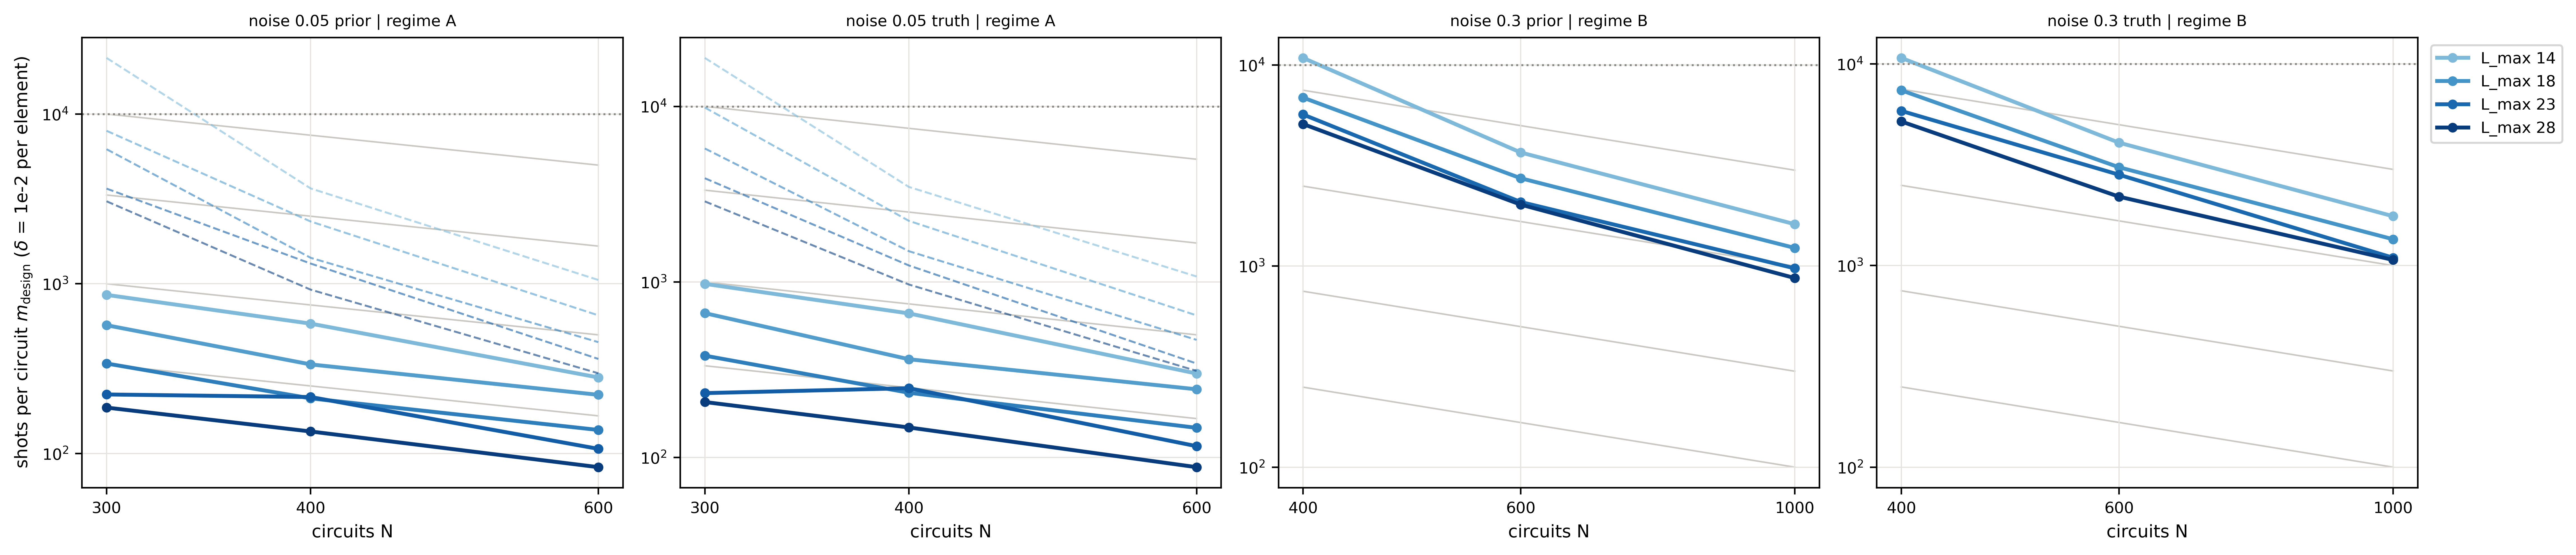

noise 0.05 prior (regime A):


,L_max,N,m design,binding,m LAN,m vT,m rate,N m (1e6),estimable %,feasible
0,14,300,859.9,vT,21395.9,859.9,13475262.5,0.3,100.0,True
1,14,400,582.2,vT,3643.2,582.2,2277576.2,0.2,100.0,True
2,14,600,280.6,vT,1052.8,280.6,558057.7,0.2,100.0,True
3,18,300,570.0,vT,7962.8,570.0,4421263.8,0.2,100.0,True
4,18,400,334.8,vT,2326.9,334.8,2030877.4,0.1,100.0,True
5,18,600,221.8,vT,651.7,221.8,279435.4,0.1,100.0,True
6,23,300,339.1,vT,6202.2,339.1,4055436.0,0.1,100.0,True
7,23,400,211.3,vT,1422.0,211.3,957334.6,0.1,100.0,True
8,23,600,137.7,vT,453.0,137.7,243366.7,0.1,100.0,True
9,28,300,222.8,vT,3635.2,222.8,2427018.1,0.1,100.0,True


noise 0.05 truth (regime A):


,L_max,N,m design,binding,m LAN,m vT,m rate,N m (1e6),estimable %,feasible
0,14,300,975.8,vT,18880.9,975.8,8279151.1,0.3,100.0,True
1,14,400,662.1,vT,3476.8,662.1,1483072.3,0.3,100.0,True
2,14,600,300.9,vT,1074.3,300.9,394033.5,0.2,100.0,True
3,18,300,664.5,vT,9848.8,664.5,3614584.6,0.2,100.0,True
4,18,400,362.9,vT,2228.2,362.9,1199357.3,0.1,100.0,True
5,18,600,244.8,vT,645.1,244.8,200863.3,0.1,100.0,True
6,23,300,380.5,vT,5758.1,380.5,2422901.1,0.1,100.0,True
7,23,400,233.9,vT,1497.0,233.9,727384.2,0.1,100.0,True
8,23,600,147.7,vT,468.0,147.7,160949.4,0.1,100.0,True
9,28,300,232.8,vT,3897.8,232.8,2037559.9,0.1,100.0,True


noise 0.3 prior (regime B):


,L_max,N,m design,binding,m LAN,m vT,m rate,N m (1e6),estimable %,feasible
0,14,400,10856.1,LAN,10856.1,6178.6,7067.2,4.3,100.0,False
1,14,600,3675.6,LAN,3675.6,2332.1,3220.4,2.2,100.0,True
2,14,1000,1616.2,LAN,1616.2,1156.3,1251.1,1.6,100.0,True
3,18,400,6889.6,LAN,6889.6,4489.8,6272.6,2.8,100.0,True
4,18,600,2736.7,LAN,2736.7,1784.1,2178.1,1.6,100.0,True
5,18,1000,1231.4,LAN,1231.4,817.9,1124.7,1.2,100.0,True
6,23,400,5678.7,LAN,5678.7,2671.8,4596.7,2.3,100.0,True
7,23,600,2084.8,LAN,2084.8,1426.0,2058.0,1.3,100.0,True
8,23,1000,975.0,LAN,975.0,639.8,959.8,1.0,100.0,True
9,28,400,5090.7,LAN,5090.7,2762.4,4244.1,2.0,100.0,True


noise 0.3 truth (regime B):


,L_max,N,m design,binding,m LAN,m vT,m rate,N m (1e6),estimable %,feasible
0,14,400,10718.5,LAN,10718.5,5977.2,5246.3,4.3,100.0,False
1,14,600,4072.3,LAN,4072.3,2823.4,2381.0,2.4,100.0,True
2,14,1000,1757.8,LAN,1757.8,1240.6,922.9,1.8,100.0,True
3,18,400,7401.7,LAN,7401.7,4684.9,4015.8,3.0,100.0,True
4,18,600,3075.2,LAN,3075.2,1914.1,1458.0,1.8,100.0,True
5,18,1000,1350.9,LAN,1350.9,980.0,650.6,1.4,100.0,True
6,23,400,5852.5,LAN,5852.5,3833.9,2929.0,2.3,100.0,True
7,23,600,2824.1,LAN,2824.1,1945.3,1457.8,1.7,100.0,True
8,23,1000,1093.5,LAN,1093.5,776.5,565.8,1.1,100.0,True
9,28,400,5185.0,LAN,5185.0,3499.3,2534.3,2.1,100.0,True


In [9]:
fig, axes = plt.subplots(1, len(POINTS), figsize=(4.6 * len(POINTS), 4.0), dpi=500)
for ax, key in zip(axes, POINTS):
    t, (lab, cap) = req[key], regimes[key]
    Ls = sorted(t["L_max"].unique())
    shades = plt.cm.Blues(np.linspace(0.45, 0.95, len(Ls)))
    for c, L in zip(shades, Ls):
        u = t[t["L_max"] == L].sort_values("N")
        ax.plot(u["N"], u["m design"], "o-", color=c, ms=4, lw=2, label=f"L_max {L}")
        if lab == "A":
            ax.plot(u["N"], u["m LAN"], "--", color=c, lw=1, alpha=0.6)
    Ns = np.array(sorted(t["N"].unique()), float)
    for budget in (1e5, 3e5, 1e6, 3e6):
        ax.plot(Ns, budget / Ns, color="#c9c8c3", lw=0.8, zorder=0)
    ax.axhline(m_cap, color="#8a8984", ls=":", lw=1)
    ax.set(xscale="log", yscale="log", xlabel="circuits N", title=f"noise {key[0]} {key[1]} | regime {lab}")
    ax.set_xticks(Ns); ax.set_xticklabels([int(n) for n in Ns]); ax.minorticks_off()
    ax.grid(True, color="#e4e3df", lw=0.6)
axes[0].set_ylabel(r"shots per circuit $m_{\rm design}$ ($\delta$ = 1e-2 per element)")
axes[-1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

for key in POINTS:
    print(f"noise {key[0]} {key[1]} (regime {regimes[key][0]}):")
    display(req[key][["L_max", "N", "m design", "binding", "m LAN", "m vT", "m rate", "N m (1e6)", "estimable %", "feasible"]].round(1))

## T4: does the prior guess give the same design as the truth?

The table shows the ratio $m_{\rm design}$(prior) / $m_{\rm design}$(truth) per $(L_{\max}, N)$; values near 1 mean the design does not depend on knowing the truth. Below it, the cheapest design in total shots, at the truth and at the prior.

In [3]:
for s in (0.05, 0.3):
    a, b = req[(s, "prior")].set_index(["L_max", "N"]), req[(s, "truth")].set_index(["L_max", "N"])
    print(f"noise {s}: m_design(prior) / m_design(truth)")
    display((a["m design"] / b["m design"]).unstack("N").round(2))
    for pt in ("truth", "prior"):
        t = req[(s, pt)][req[(s, pt)]["feasible"]]
        i = t["N m (1e6)"].idxmin()
        print(f"  cheapest in total shots at the {pt}: L_max {t.at[i, 'L_max']}, N {t.at[i, 'N']}, m {t.at[i, 'm design']:.0f}, N m = {t.at[i, 'N m (1e6)']:.2f}e6")

noise 0.05: m_design(prior) / m_design(truth)


N,300,400,600
L_max,,,
14,0.88,0.88,0.93
18,0.86,0.92,0.91
23,0.89,0.90,0.93
28,0.96,0.87,0.92
32,0.90,0.91,0.94


  cheapest in total shots at the truth: L_max 32, N 600, m 88, N m = 0.05e6
  cheapest in total shots at the prior: L_max 32, N 600, m 83, N m = 0.05e6
noise 0.3: m_design(prior) / m_design(truth)


N,400,600,1000
L_max,,,
14,1.01,0.90,0.92
18,0.93,0.89,0.91
23,0.97,0.74,0.89
28,0.98,0.92,0.82


  cheapest in total shots at the truth: L_max 28, N 1000, m 1066, N m = 1.07e6
  cheapest in total shots at the prior: L_max 28, N 1000, m 872, N m = 0.87e6


## Marginal returns: depth and circuits

The tables show local exponents of $m_{\rm design}$:
- $d\log m/d\log L_{\max}$ per $N$ (rows);
- $d\log m/d\log N$ per $L_{\max}$.

$-1$ means doubling halves $m$. Only for the prior points, which are what a real design would use.

In [4]:
for s in (0.05, 0.3):
    t = req[(s, "prior")]
    print(f"noise {s} prior: d log m / d log L_max")
    display(pdz.depth_returns(t).round(2))
    out = {}
    for L, u in t.groupby("L_max"):
        u = u.sort_values("N")
        Nn, m = u["N"].to_numpy(float), u["m design"].to_numpy(float)
        out[L] = pd.Series(np.diff(np.log(m)) / np.diff(np.log(Nn)), index=[f"{int(x)}->{int(y)}" for x, y in zip(Nn[:-1], Nn[1:])])
    print(f"noise {s} prior: d log m / d log N")
    display(pd.DataFrame(out).T.rename_axis("L_max").round(2))

noise 0.05 prior: d log m / d log L_max


,14->18,18->23,23->28,28->32
N,,,,
300,-1.64,-2.12,-2.14,-1.33
400,-2.20,-1.88,0.09,-3.50
600,-0.94,-1.95,-1.30,-1.86


noise 0.05 prior: d log m / d log N


,300->400,400->600
L_max,,
14,-1.36,-1.80
18,-1.85,-1.02
23,-1.64,-1.06
28,-0.12,-1.73
32,-1.13,-1.19


noise 0.3 prior: d log m / d log L_max


,14->18,18->23,23->28
N,,,
400,-1.81,-0.79,-0.56
600,-1.17,-1.11,-0.15
1000,-1.08,-0.95,-0.57


noise 0.3 prior: d log m / d log N


,400->600,600->1000
L_max,,
14,-2.67,-1.61
18,-2.28,-1.56
23,-2.47,-1.49
28,-2.28,-1.65


## Cost: circuits are more expensive than shots

The cheapest feasible design ($m\le10^4$) for the cost $N\,(r+m_{\rm design})$, for several circuit costs $r$ given in shots. $r=0$ is the total number of shots. The grid is coarse ($N$ and $L_{\max}$ as scanned), so this picks the best grid point, not a continuous optimum.

Below that, the same for **all 1440 elements at once** (Bonferroni, $z=4.14$), which costs about $(4.14/1.96)^2=4.5$ times more shots.

In [5]:
z_all = pdz.bonferroni_z(1440)
for s in (0.05, 0.3):
    print(f"noise {s} prior, each element at 95%:")
    display(pdz.cost_table(req[(s, "prior")], r_list).round(1))
    rows, meta = scans[(s, "prior")]
    print(f"noise {s} prior, all elements at once (z = {z_all:.2f}):")
    display(pdz.cost_table(pdz.design_requirements(rows, meta, delta, z_all, m_max=m_cap), r_list).round(1))

noise 0.05 prior, each element at 95%:


,circuit cost r (shots),L_max,N,m design,cost (1e6 shot-equivalents)
0,0.0,32,600,83.1,0.0
1,100.0,32,300,186.5,0.1
2,1000.0,32,300,186.5,0.4
3,10000.0,32,300,186.5,3.1


noise 0.05 prior, all elements at once (z = 4.14):


,circuit cost r (shots),L_max,N,m design,cost (1e6 shot-equivalents)
0,0.0,32,600,494.6,0.3
1,100.0,32,600,494.6,0.4
2,1000.0,32,300,1130.3,0.6
3,10000.0,32,300,1130.3,3.3


noise 0.3 prior, each element at 95%:


,circuit cost r (shots),L_max,N,m design,cost (1e6 shot-equivalents)
0,0.0,28,1000,872.2,0.9
1,100.0,28,1000,872.2,1.0
2,1000.0,28,600,2023.0,1.8
3,10000.0,28,400,5090.7,6.0


noise 0.3 prior, all elements at once (z = 4.14):


,circuit cost r (shots),L_max,N,m design,cost (1e6 shot-equivalents)
0,0.0,28,1000,3891.5,3.9
1,100.0,28,1000,3891.5,4.0
2,1000.0,28,1000,3891.5,4.9
3,10000.0,28,600,9026.0,11.4


## Drift caps the useful number of shots

The derivation follows VALIDITY 4.7 item 3:
- Setup: an outcome probability $p$ is constant during the $m$ shots of a circuit but drifts between circuits, with mean $\bar p$, $\bar q=1-\bar p$, and variance $V$.
- The counts then have variance $m\bar p\bar q\,\omega$ with $\omega=1+(m-1)V/(\bar p\bar q)$.
- So $m$ drifting shots carry the information of $m_{\rm eff}=m/\omega$ undrifted ones, and $m_{\rm eff}\to\bar p\bar q/V$ as $m\to\infty$.

Shots beyond about $\bar p\bar q/V$ buy almost nothing. Circuits are not capped this way if the drift is independent between circuits. Measure $V$ by repeating a few circuits spread over the run.

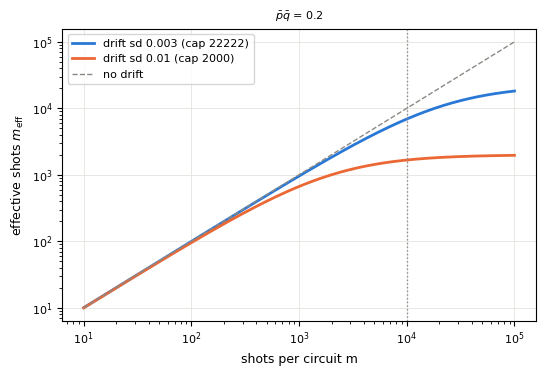

In [6]:
m = np.logspace(1, 5, 200)
pq = 0.2
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for sd, c in [(0.003, "#2a78d6"), (0.01, "#eb6834")]:
    V = sd ** 2
    ax.plot(m, m / (1 + (m - 1) * V / pq), color=c, lw=2, label=f"drift sd {sd} (cap {pq / V:.0f})")
ax.plot(m, m, color="#8a8984", ls="--", lw=1, label="no drift")
ax.axvline(m_cap, color="#8a8984", ls=":", lw=1)
ax.set(xscale="log", yscale="log", xlabel="shots per circuit m", ylabel=r"effective shots $m_{\rm eff}$", title=r"$\bar p\bar q$ = 0.2")
ax.grid(True, color="#e4e3df", lw=0.6); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## T3: refits at the chosen designs

The outputs of [`scripts/18_ptm_refit_check.py`](identifiability_and_cramer_rao/scripts/18_ptm_refit_check.py) for the refits of [`scripts/17_ptm_refit_runner.py`](identifiability_and_cramer_rao/scripts/17_ptm_refit_runner.py), 10 per design, saved as `data/18_<design>_output.txt`.

**What to look for:**
- **rmse/σ:** median close to 1 for the width that sets the design. That is LAN in regime B and vT in regime A. Below 1 means conservative.
- **Pairs within δ:** at least 95% of (element, dataset) pairs within $\delta$.
- **Λ:** mean close to $n_{\rm id}=624$ in regime B, meaning the asymptotic regime; at the noise-0.05 reference it was 241.
- **Optimizer tolerance:** the default-versus-tight shift is well below one width.

In [7]:
for f in sorted(DATA.glob("18_*_output.txt")):
    print(f"===== {f.name}")
    print("\n".join(l for l in f.read_text().splitlines() if "INFO" not in l and "xla" not in l and "Warning" not in l and "x_bar" not in l))

===== 18_conv_s0.3_N600_m2200_L28_output.txt
conv_s0.3_N600_m2200_L28_d12345: 10 estimates, 0% converged; rank 624; tau0 = 3.265e-02; an rmse is known to about +-24%
actual error: median rmse over elements 2.78e-03, max 7.30e-03; max |error| 1.16e-02

1) Fisher predictions versus the actual errors of the Pauli transfer matrix elements
  LAN                        max sigma 5.30e-03  predicted 1.96 max sigma 1.04e-02  median rmse/sigma  0.81  5%-95% 0.50-1.25  coverage(95%)  97.3%
  van Trees tau = 6.529e-02  max sigma 4.51e-03  predicted 1.96 max sigma 8.84e-03  median rmse/sigma  0.90  5%-95% 0.56-1.39  coverage(95%)  95.7%
  van Trees tau = 3.265e-02  max sigma 3.59e-03  predicted 1.96 max sigma 7.04e-03  median rmse/sigma  1.05  5%-95% 0.65-1.63  coverage(95%)  91.7%

2) the goal, delta = 1e-02
  (element, dataset) pairs with |error| <= delta: 99.8%   (target: >= 95%)
  datasets with all 1440 elements within delta: 10.0%
  worst element: rmse 7.30e-03, 1.96 rmse 1.43e-02

3) small C

## Conclusions (run of 2026-11-17; one design seed per scan point; T3 with 10 refits per design)

$\delta=10^{-2}$ per PTM element at 95% ($z=1.96$). Numbers from the tables above and from the T3 outputs.

**1. The design does not depend on knowing the truth (T4).**
- At the prior guess, $m_{\rm design}$ is 0.74–1.01 times its value at the truth, typically about 0.9. So the prior is slightly optimistic: **multiply $m$ by about 1.2.**
- The best $(L_{\max}, N)$ are the same at prior and truth.

**2. Depth.**
- **Noise 0.05:** the gain continues up to $L_{\max}=32$; the local exponents are about $-1$ to $-2$ (noisy with one seed).
- **Noise 0.3:** the gain flattens after 23. From 23 to 28 the exponent is $-0.15$ to $-0.57$, and the depth check showed no gain beyond that.
- Use $L_{\max}=32$ and 28 respectively.

**3. Circuits against shots.**
- In both regimes $m_{\rm design}$ falls faster than $1/N$: $d\log m/d\log N=-1$ to $-1.8$ at noise 0.05 and $-1.5$ to $-2.7$ at noise 0.3. In total shots, more circuits are always cheaper over the scanned range.
- With a circuit cost $r$ (in shots), the cheapest design moves to small $N$:
  - noise 0.05: $N=300$ already for $r\ge100$ (prior: $L_{\max}=32$, $m\approx190$);
  - noise 0.3: $N=600$ for $r\approx10^3$ ($m\approx2000$) and $N=400$ for $r\approx10^4$ ($m\approx5100$).
- With $m\le10^4$, only $N=400$ at $L_{\max}=14$ is infeasible at noise 0.3 (per element). For all 1440 elements at once ($\times4.5$ in $m$), $N\ge600$ is needed there.

**4. T3: refits confirm the regime picture.**

| | noise 0.05: $L_{\max}=32$, $N=400$, $m=150$ (regime A) | noise 0.3: $L_{\max}=28$, $N=600$, $m=2200$ (regime B) | reference: noise 0.05, $L_{\max}=14$, $N=400$, $m=1000$ |
|---|---|---|---|
| median rmse/$\sigma^{\rm LAN}$ (coverage) | 0.21 (100%) | **0.81 (97%)** | 0.24 (100%) |
| median rmse/$\sigma^{\rm vT}(2\tau_0)$ (coverage) | **0.95 (94%)** | 0.90 (96%) | 0.93 (96%) |
| (element, dataset) pairs within $\delta$ | 99.1% | 99.8% | 99.9% |
| worst element, $1.96\,$rmse | $1.3\times10^{-2}$ | $1.4\times10^{-2}$ | $1.0\times10^{-2}$ |
| rates at the positivity boundary | 46% | 0% | 32% |
| $\Lambda$ / 624 (effective number of fitted parameters) | 28% | 87–88% | 39% |
| goodness of fit $N_\sigma$ | 12.8 | 1.2–1.3 | 12.7 |

- **Regime A: design to the van Trees width.** It stayed calibrated at a design other than the one where $\tau$ was calibrated (0.95, against 0.93 at the reference), and LAN was 5× conservative, as predicted.
- **Regime B: the prediction of VALIDITY is confirmed.** With resolved rates:
  - LAN moves from 4× conservative to nearly calibrated (0.81);
  - no rate collapses;
  - $\Lambda$ approaches $n_{\rm id}$;
  - the Wilks goodness-of-fit test becomes usable ($N_\sigma\approx1$ instead of 13).
- **The worst element** comes out about 1.3–1.4× above $\delta$ in both designs. With $R=10$ refits each rmse is uncertain by ±24%, and the maximum over 1440 elements selects the high ones. For "every element within $\delta$", add a margin of about 1.5× in $m$.

**5. The optimizer is the open issue at the noise-0.3 design.**
- Neither the default settings (20 outer iterations, 1 nat) nor script 07's "converged" settings (60 outer iterations, $10^{-4}$ nat, relative precision $10^{-8}$) met a convergence criterion at $N=600$, $m=2200$, $L_{\max}=28$.
- Estimates of the same dataset differ between the two stopping points by a median of 0.16–0.47 and up to 2.6 LAN widths per element.
- The aggregate statistics barely change (LAN ratio 0.81 in both; worst element $1.9$ versus $1.4\times10^{-2}$). The Fisher prediction of the statistical error is therefore confirmed in aggregate, but individual elements carry an optimizer error of comparable size.
- At noise 0.05 all fits converged, and 1 nat moved the estimates by at most 0.13 widths (20 reference datasets).
- **Before using such a design, the optimization must converge reliably at large $m$** (VALIDITY assumption E2).

**6. Recommended designs**, with the margins of items 1 and 4 ($\times1.2$ for the prior, $\times1.5$ for the worst element):
- **noise 0.05 (hardware-like):** $L_{\max}=32$, $N=400$, $m\gtrsim300$ (0.12M shots). Shots are cheap here, so anything up to $m\sim10^3$ is inexpensive insurance, until drift caps the useful $m$.
- **noise 0.3:** $L_{\max}=28$, with $N=600$ and $m\approx4000$, or $N=1000$ and $m\approx1600$ if circuits are cheap. Both need a converging optimizer.
